# Wave-event locations in the Wheeler–Kiladis plane

**Question:** Do the fitted $(k,\omega)$ locations of 2σ envelope events
concentrate where the same records have enhanced WK-style spectral power?

Each figure has a panel for Kelvin, MRG, n=0 EIG, n=1 ER and n=1 WIG.
Colors count events, black contours show the saved 96-day WK power/background
ratio, and orange curves show resting-state 12/25/50 m dispersion relations.
NOAA is followed by equally weighted Historical and AMIP ensemble views.

The main axes use conventional WK coordinates: global $K=kR$ and positive
$f=\omega\,86400/(2\pi)$ in cycles/day. Secondary axes give dimensional $k$
and $\omega$. Negative $K$ is westward; positive $K$ is eastward.
[Wheeler and Kiladis (1999)](https://doi.org/10.1175/1520-0469%281999%29056%3C0374%3ACCEWAO%3E2.0.CO%3B2)
provides the spectral-analysis reference; the contours here use the project's
saved WK-style implementation.

## Inputs, weighting and selections

- Daily 1990–2010, the audited **2σ component catalogs**: NOAA, 34 Historical and 25 AMIP records, one member per simulation.
- Each successful fit contributes one count, including fits whose assigned dispersion branch has no valid depth. No depth restriction is imposed. The second set of figures uses the existing `keep_for_histogram` quality screen.
- Integer-centered K bins have width 1; frequency centers lie on the 1/96 cycles/day WK grid. The zero/Nyquist endpoint cells have half width. Fitted coordinates remain continuous; binning does not imply integer-only fits or 96-day event durations.
- Colors are **percent of each source/wave's selected events per bin**. Model maps average those percentages with equal source weights. White cells contain no events. Every figure uses the same logarithmic color scale.
- WK contours divide symmetric or antisymmetric mean power by the saved shared smoothed background, choosing the wave's OLR symmetry. Ensemble contours average each model's normalized ratio equally. Levels 1.1, 1.3 and 1.5 are descriptive power ratios.
- Spectra use exact 96-day segments with 60-day overlap, latitude-power averaging over 15°S–15°N, and ten 1-2-1 smoothing passes in K and frequency. Events use symmetry projection over 20°S–20°N followed by a northern 0–20° mean. The latitude reductions differ, so the two diagnostics need not have identical shapes.
- Dashed rectangles mark the **carrier-fit search limits**. Cells can straddle a limit. Curves assume zero background wind and the assigned branch. The hatched top bin includes daily Nyquist; exact Nyquist direction is ambiguous and its WK contour is excluded.

Extraction: `python scripts/codex_wave_event_komega/extract.py` on Levante.
No raw-data processing, event refitting or Gaussian-realization calculation is
needed for these plots. [Reproduction details](../scripts/codex_wave_event_komega/README.md).

In [1]:
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from IPython.display import display
from src.paths import DATA_DIR

INPUT = DATA_DIR / "event_threshold_comparison/wave_event_komega_sigma2"
audit = json.loads((INPUT / "audit.json").read_text())
assert audit["status"] == "complete" and audit["detection_sigma"] == 2
assert audit["catalogs"] == 300 and audit["source_records"] == 60
with xr.open_dataset(INPUT / "histograms_and_wk.nc", decode_timedelta=False) as source:
    data = source.load()
index = pd.read_csv(INPUT / "catalog_index.csv")
assert len(index) == 300 and index.detection_sigma.eq(2).all()
assert not index.duplicated(["model", "experiment", "member", "wave"]).any()
np.testing.assert_array_equal(data.event_count.sum(("frequency", "K")), data.selected_events)
assert (data.selected_events > 0).all()
display(index.groupby(["experiment", "wave"])[["successful_fits", "screened_events"]].sum())


successful_fits  screened_events
experiment   wave                                    
amip         Kelvin            61347            10861
             MRG               53888            11271
             n0EIG             67615            21910
             n1ERW             23677             2598
             n1WIG             70401            28683
historical   Kelvin            83891            14553
             MRG               74880            15622
             n0EIG             94241            29736
             n1ERW             34062             4144
             n1WIG             98217            39783
observations Kelvin             2573              530
             MRG                2389              475
             n0EIG              2989              901
             n1ERW               887              117
             n1WIG              3045             1300

In [2]:
WAVES = ["Kelvin", "MRG", "n0EIG", "n1ERW", "n1WIG"]
LABELS = {"Kelvin": "Kelvin", "MRG": "MRG", "n0EIG": "n=0 EIG", "n1ERW": "n=1 ER", "n1WIG": "n=1 WIG"}
GROUPS = [("observations", "NOAA OLR"), ("historical", "Historical model mean"), ("amip", "AMIP model mean")]
SELECTIONS = {"fit_success": "all successful fits", "keep_for_histogram": "existing fit-quality subset"}
WK_LEVELS = [1.1, 1.3, 1.5]
DEPTH_STYLES = {12.: ":", 25.: "--", 50.: "-."}
CURVE_COLOR = "#d45e00"
R = float(data.attrs["earth_radius_m"])
K_EDGES = np.r_[data.K_lower.values, data.K_upper.values[-1]]
F_EDGES = np.r_[data.f_lower.values, data.f_upper.values[-1]]

heatmaps, wk_ratios, group_records = {}, {}, {}
for experiment, _ in GROUPS:
    records = data.record.values[data.experiment.values == experiment]
    group_records[experiment] = records
    part = data.sel(record=records)
    # Normalize each record before taking an ensemble mean.
    for selection in SELECTIONS:
        percent = 100 * part.event_count.sel(selection=selection) / part.selected_events.sel(selection=selection)
        heatmaps[experiment, selection] = percent.mean("record")
    wk_ratios[experiment] = (part.wk_mean_power / part.wk_background).mean("record")
assert [len(group_records[e]) for e, _ in GROUPS] == [1, 34, 25]
maximum = max(float(values.max()) for values in heatmaps.values())
NORM = LogNorm(vmin=.01, vmax=np.ceil(maximum*10)/10)
CMAP = plt.get_cmap("Blues").copy()
CMAP.set_bad("white")
CMAP.set_under("#f4f8fc")

def plot_wave_panels(experiment, selection):
    """Plot five family histograms against the matching WK symmetry and theory."""
    fig, axes = plt.subplots(3, 2, figsize=(15.5, 13), layout="constrained")
    records = group_records[experiment]
    for wave, ax in zip(WAVES, axes.flat):
        values = heatmaps[experiment, selection].sel(wave=wave).values
        mesh = ax.pcolormesh(K_EDGES, F_EDGES, np.ma.masked_less_equal(values, 0),
                             shading="flat", cmap=CMAP, norm=NORM, rasterized=True)
        lo_k, hi_k = [float(data[f"fit_K_{side}"].sel(wave=wave)) for side in ("min", "max")]
        lo_f, hi_f = [float(data[f"fit_f_{side}"].sel(wave=wave)) for side in ("min", "max")]
        symmetry = str(data.wave_symmetry.sel(wave=wave).item())
        ratio = wk_ratios[experiment].sel(symmetry=symmetry)
        # Include the WK cell containing a fit at a search boundary.
        nearby = ((ratio.K >= lo_k-.5) & (ratio.K <= hi_k+.5)
                  & (ratio.wk_frequency >= lo_f-.5/96) & (ratio.wk_frequency <= hi_f+.5/96))
        field = np.ma.masked_invalid(ratio.where(nearby).values)
        levels = [v for v in WK_LEVELS if field.min() <= v <= field.max()]
        if levels:
            contours = ax.contour(data.K.values, data.wk_frequency.values, field,
                                   levels=levels, colors="k", linewidths=.8)
            ax.clabel(contours, fmt="%.1f", inline=True, fontsize=6)
        for depth, linestyle in DEPTH_STYLES.items():
            curve = data.curve_frequency.sel(wave=wave, equivalent_depth=depth)
            visible = np.where((curve > 0) & (curve <= .5), curve, np.nan)
            ax.plot(data.curve_K, visible, color=CURVE_COLOR, linestyle=linestyle, linewidth=1.2)
        ax.add_patch(Rectangle((lo_k, lo_f), hi_k-lo_k, hi_f-lo_f,
                               fill=False, edgecolor=".35", linewidth=1, linestyle="--"))
        ax.axhspan(F_EDGES[-2], .5, facecolor=".85", alpha=.3, hatch="///", edgecolor=".5", linewidth=0)
        ax.axvline(0, color=".75", linewidth=.6)
        ax.set(xlim=(-15.5, 15.5), ylim=(0, .5),
               xticks=np.arange(-15, 16, 5), yticks=np.arange(0, .51, .1),
               xlabel="Global zonal wavenumber K", ylabel="Frequency f [cycles/day]")
        ax.tick_params(labelsize=8)
        ax.xaxis.label.set_size(9)
        ax.yaxis.label.set_size(9)
        top = ax.secondary_xaxis("top", functions=(lambda K: K/R*1e6, lambda k: k*1e-6*R))
        top.set_xlabel(r"k [$10^{-6}$ rad m$^{-1}$]", fontsize=8, labelpad=2)
        top.set_xticks([-2, -1, 0, 1, 2])
        top.tick_params(labelsize=7)
        right = ax.secondary_yaxis("right", functions=(
            lambda f: 2*np.pi*f/86400*1e5, lambda omega: omega*1e-5*86400/(2*np.pi)))
        right.set_ylabel(r"$\omega$ [$10^{-5}$ rad s$^{-1}$]", fontsize=8, labelpad=2)
        right.set_yticks([0, 1, 2, 3])
        right.tick_params(labelsize=7)
        totals = data.selected_events.sel(record=records, wave=wave, selection=selection).values
        n_label = f"n={int(totals[0])}" if experiment == "observations" else f"{len(records)} models; median n={np.median(totals):g}"
        ax.set_title(f"{LABELS[wave]} ({symmetry}) — {n_label}", fontsize=10, pad=34)
        ax.grid(alpha=.12, linewidth=.5)
    legend_ax = axes.flat[5]
    legend_ax.set_axis_off()
    handles = [Line2D([], [], color="k", linewidth=.8, label="WK power/background: 1.1, 1.3, 1.5")]
    handles += [Line2D([], [], color=CURVE_COLOR, linestyle=style, linewidth=1.2,
                       label=f"Resting-state h = {depth:g} m") for depth, style in DEPTH_STYLES.items()]
    handles += [Patch(facecolor="none", edgecolor=".35", linestyle="--", label="Carrier-fit search limits"),
                Patch(facecolor=".9", edgecolor=".5", hatch="///", label="Bin containing daily Nyquist")]
    legend_ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=10)
    legend_ax.text(.04, .42,
        "One event, one count; ΔK=1, Δf=1/96 day⁻¹.\n"
        "Ensembles average source-normalized histograms.\n"
        "White cells have zero events.\n"
        "All panels and figures share the color scale.\n"
        "Negative K: westward; positive K: eastward.",
        transform=legend_ax.transAxes, fontsize=10, va="top", linespacing=1.5)
    cax = legend_ax.inset_axes([.06, .07, .83, .055])
    bar = fig.colorbar(mesh, cax=cax, orientation="horizontal", extend="min")
    bar.set_label("Selected wave events per K–f bin [%], logarithmic scale", fontsize=9)
    bar.ax.tick_params(labelsize=8)
    group_label = dict(GROUPS)[experiment]
    fig.suptitle(f"{group_label} — 2σ envelope events, 1990–2010\nFitted event locations: {SELECTIONS[selection]}", fontsize=15)
    plt.show()


## All successful fits

Every successful fit enters these heatmaps once, including branch-inversion
failures. Each panel uses its corresponding symmetric/antisymmetric WK contour.
The two model ensembles average normalized source histograms rather than pooling
their events. The shared color scale supports comparison across all wave panels
and datasets.

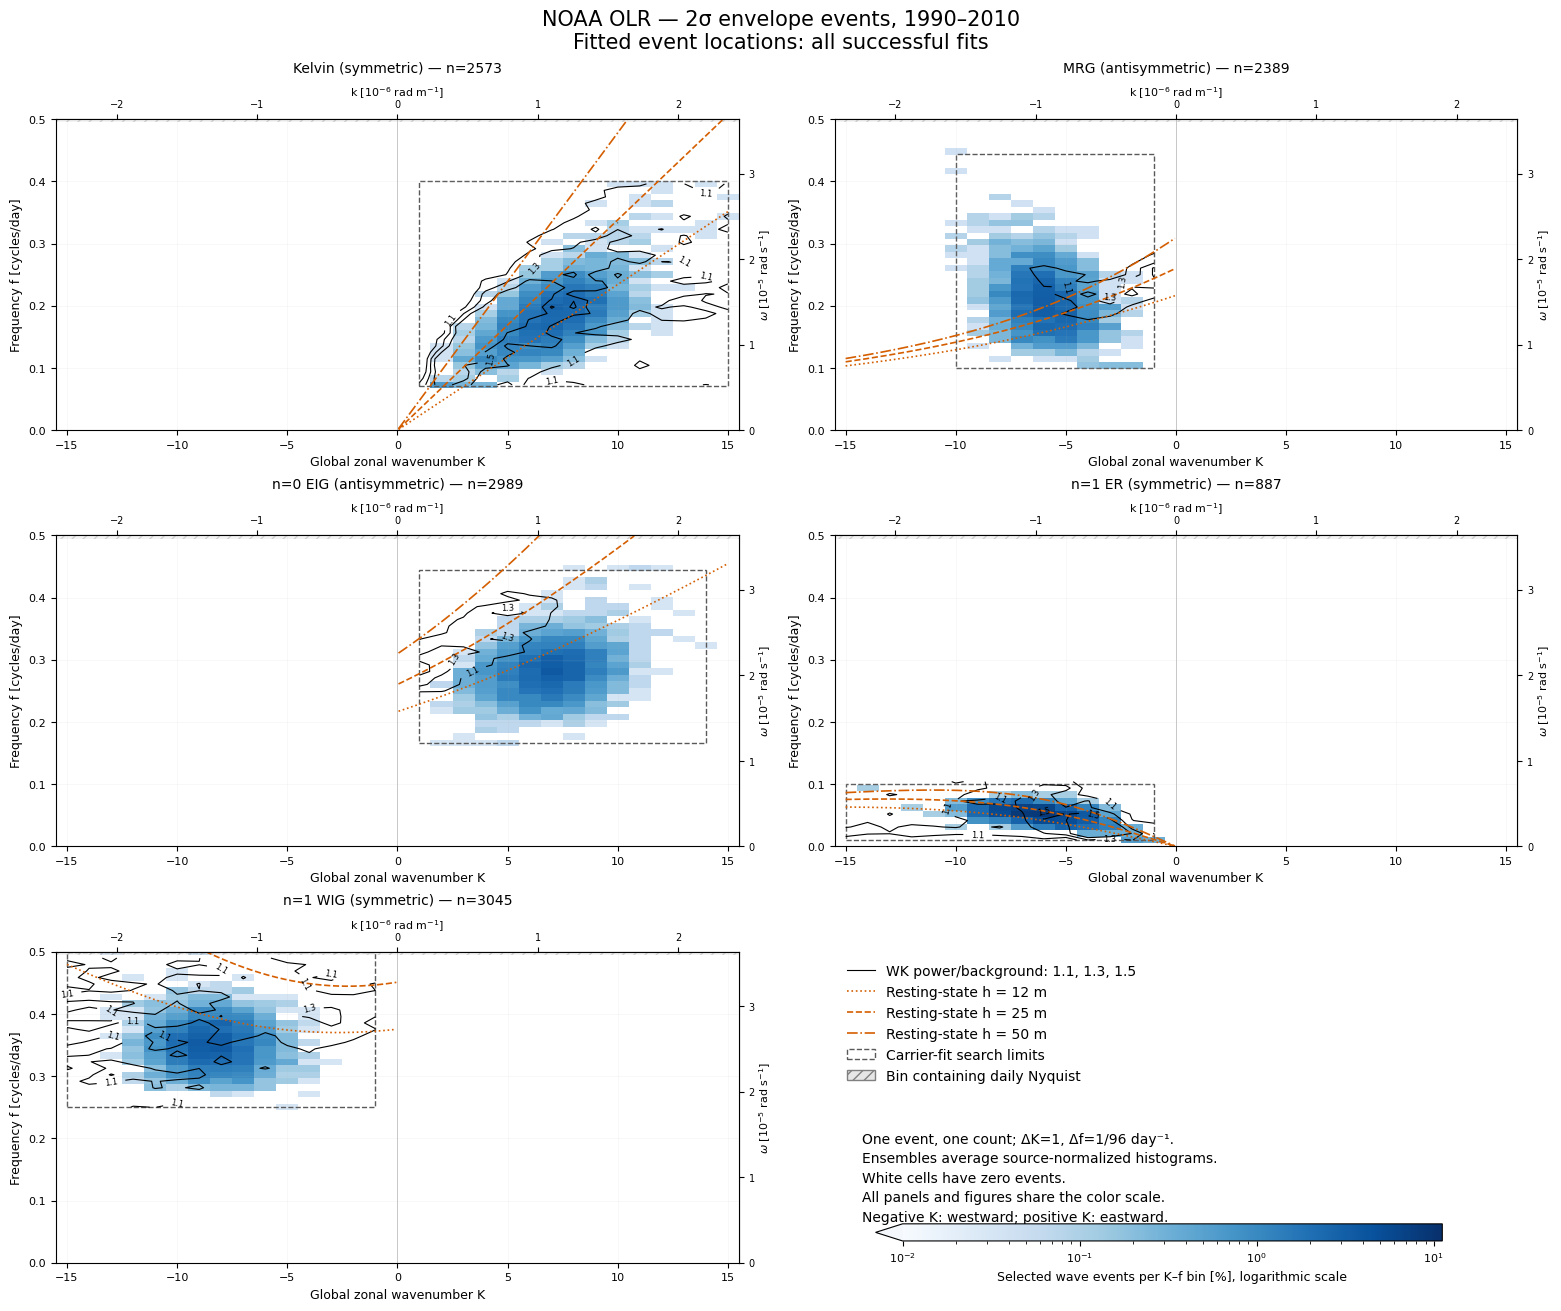

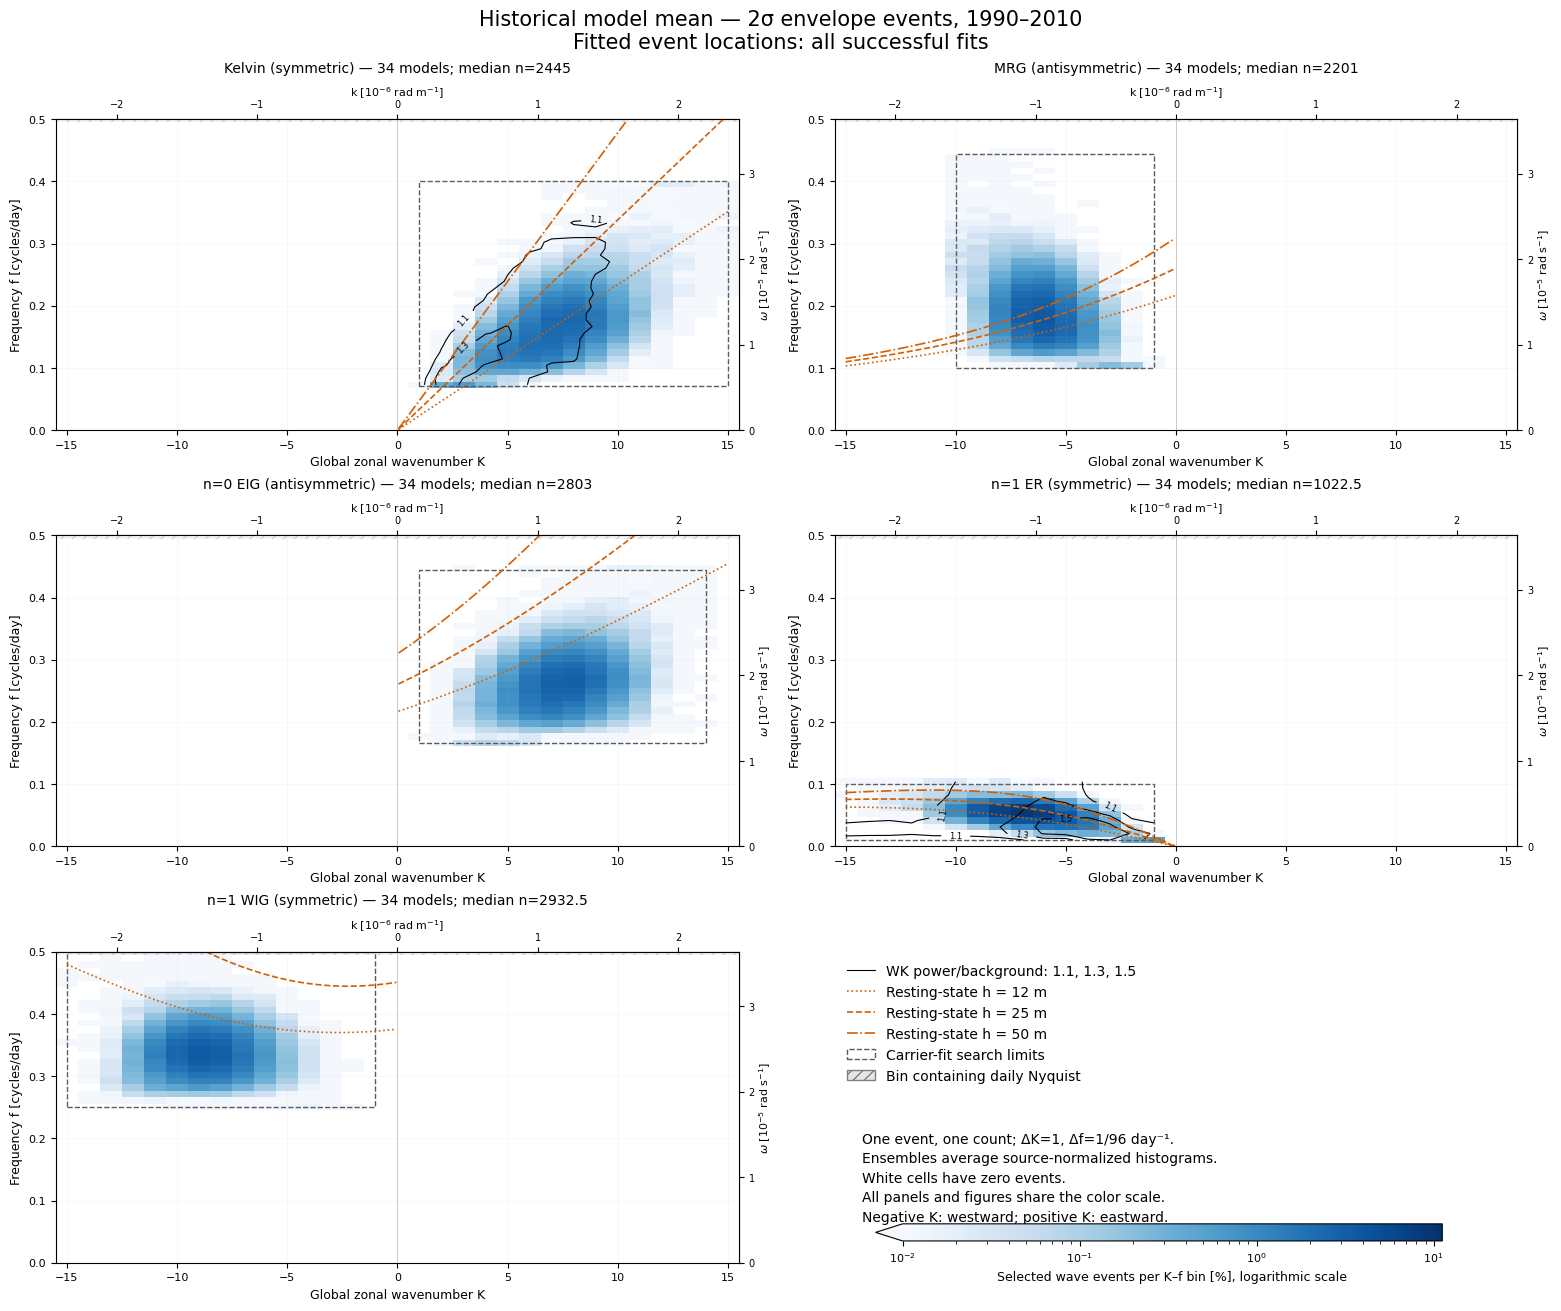

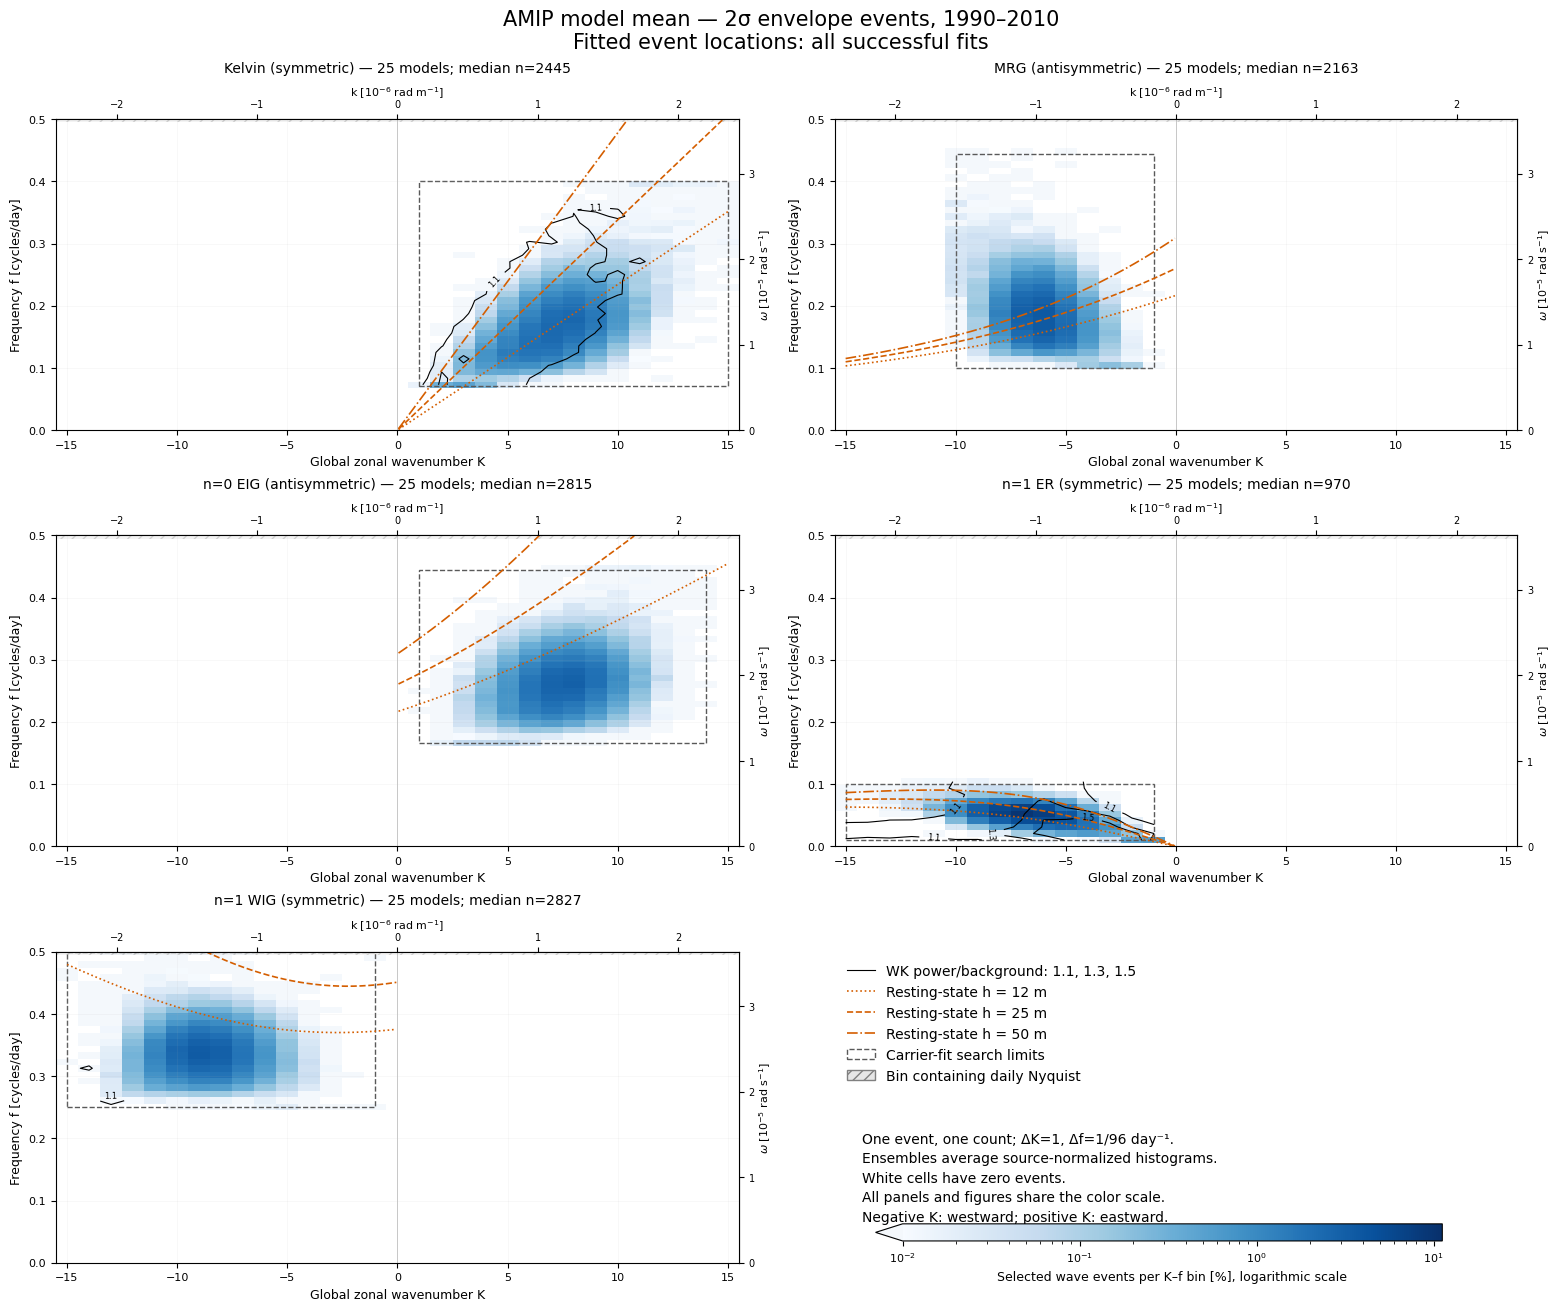

In [3]:
for experiment, _ in GROUPS:
    plot_wave_panels(experiment, "fit_success")


## Existing fit-quality subset

These figures use the same 2σ detections and apply the existing fit/depth quality
flags. Compare with the first set to see how the sampled cycles, search-edge
and branch-validity screens affect apparent spectral concentrations.

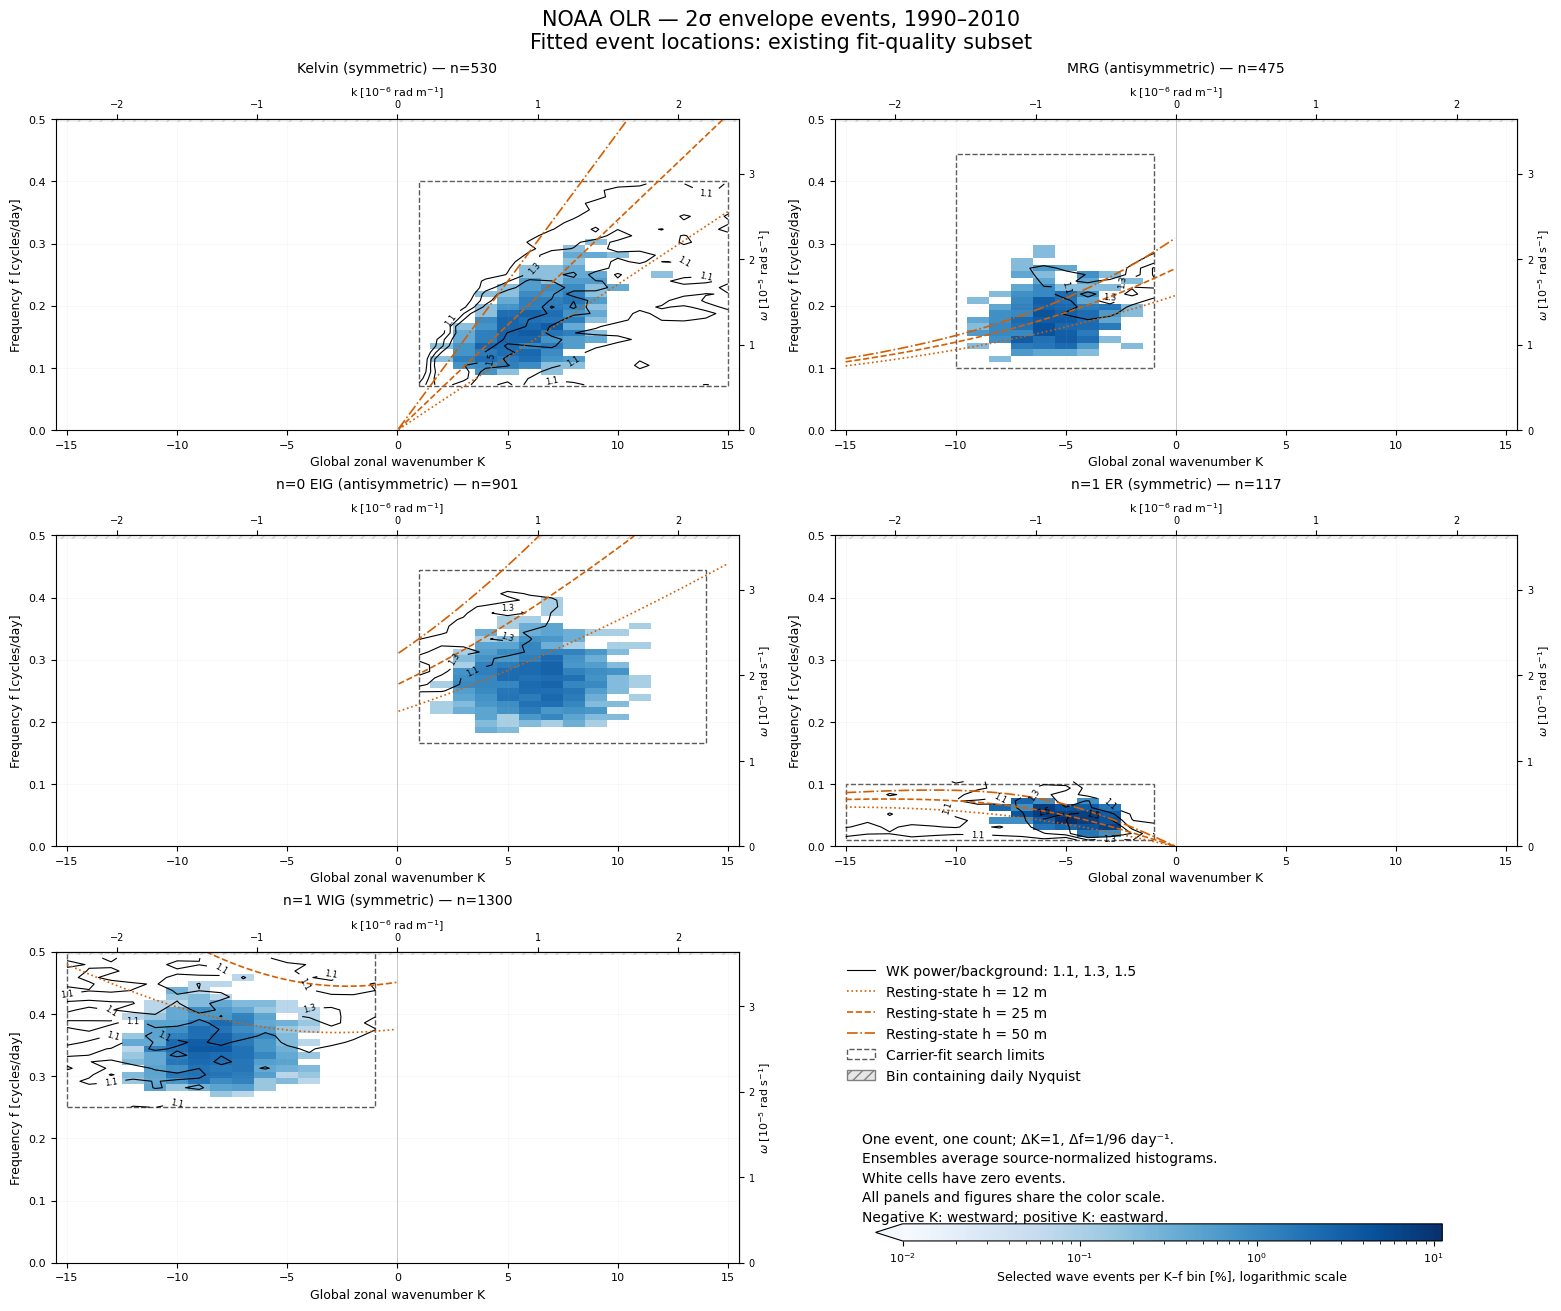

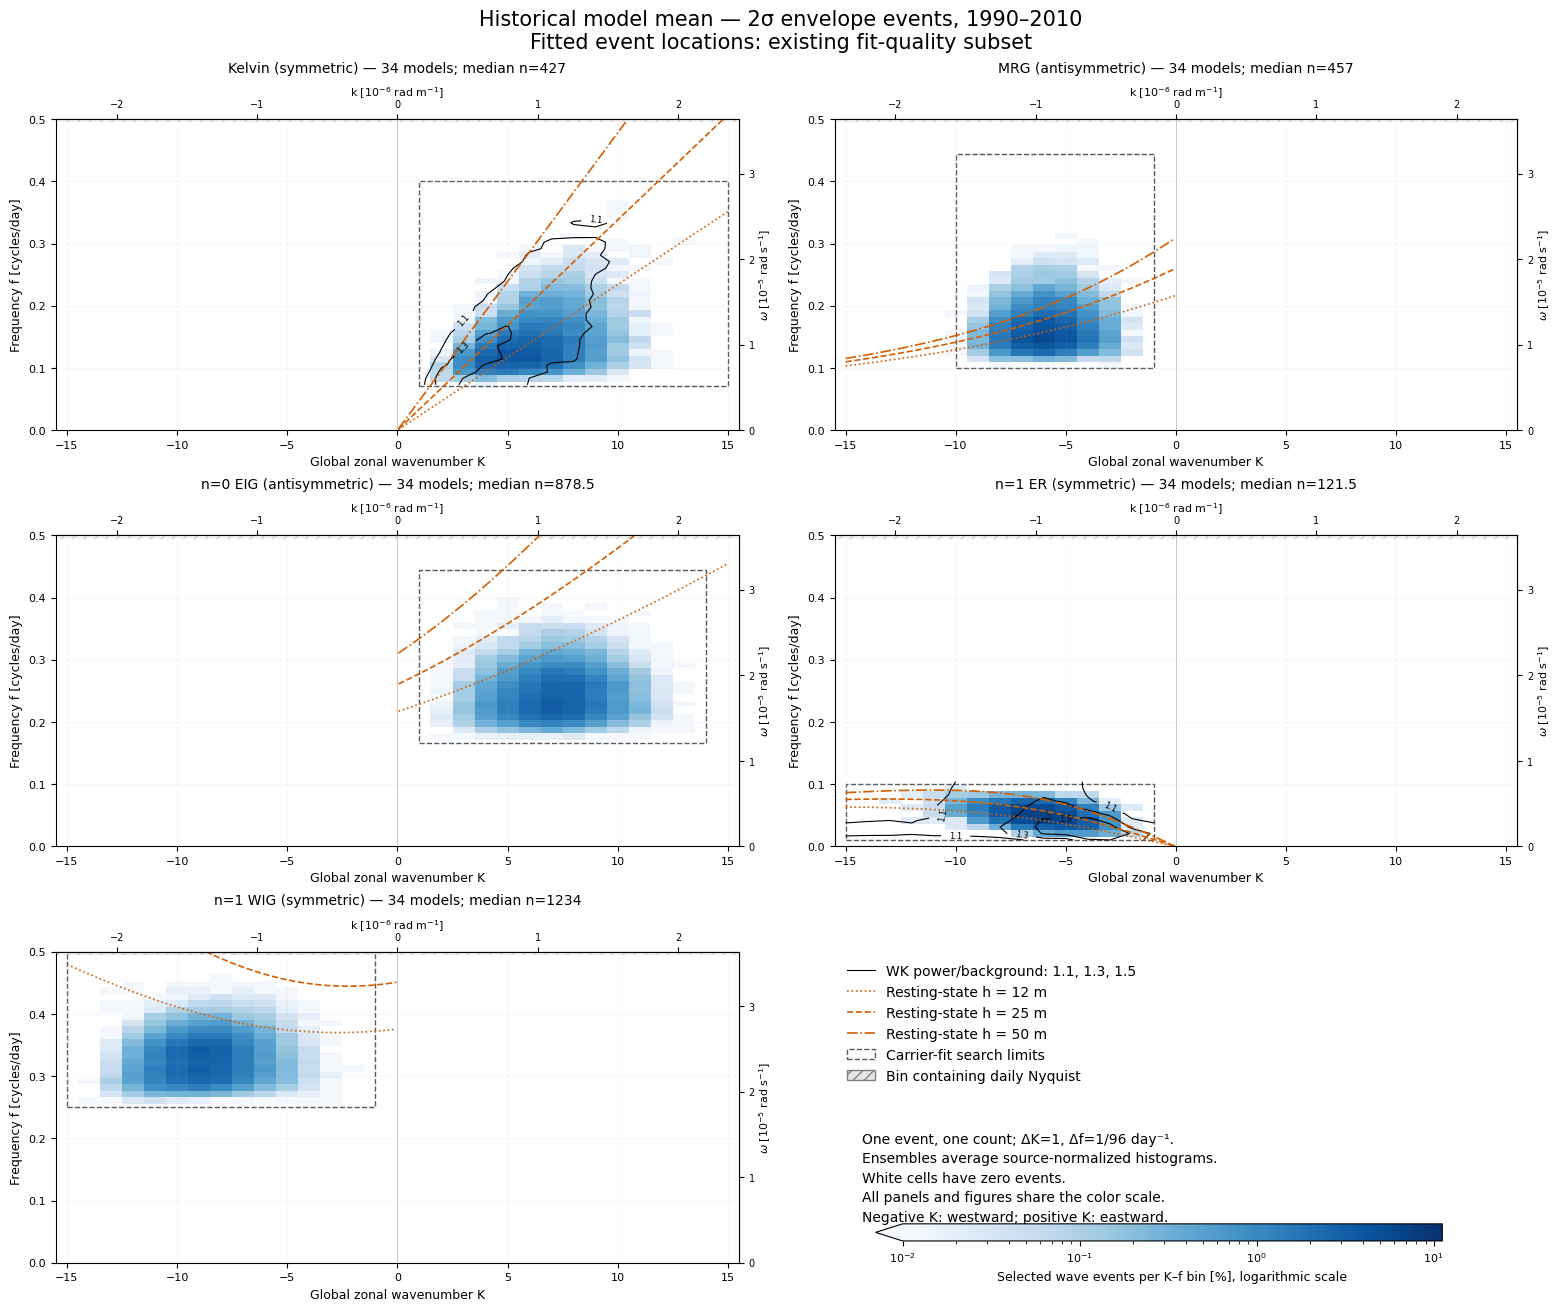

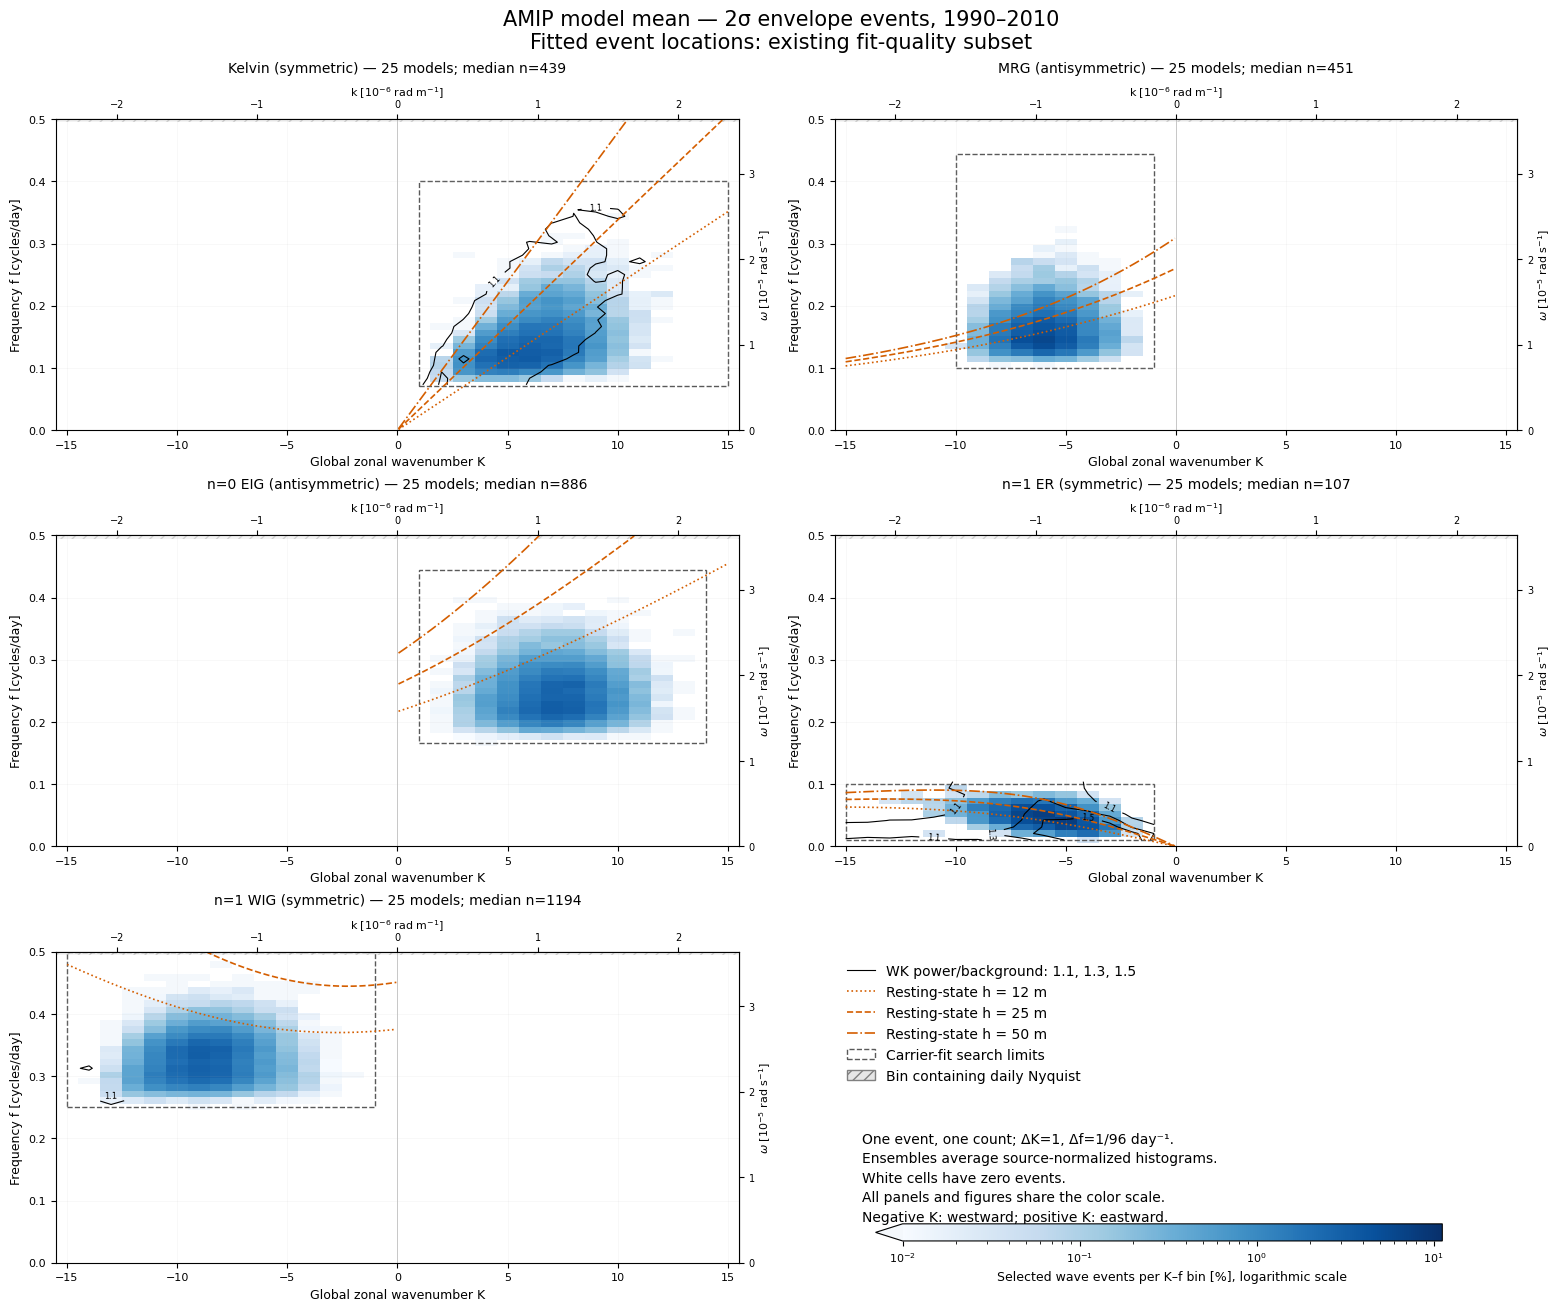

In [4]:
for experiment, _ in GROUPS:
    plot_wave_panels(experiment, "keep_for_histogram")


## Descriptive overlap with enhanced WK power

The table counts events in resolved WK cells with power/background ≥ 1.1,
as a percentage of events in those resolved cells. Zero/Nyquist endpoint cells
are excluded from this overlap calculation. Each model is compared with its
own WK spectrum before averaging percentages. This is a binned overlap
diagnostic, with shared input data and filter constraints, rather than an
independent significance or wave-identification test.

For geometric context, the table also reports the fraction of available K–f
area with WK ratio ≥ 1.1. Partial edge cells are weighted by their intersection
with the carrier-fit search rectangle. This uniform-area reference describes
passband geometry; it does not supply a physical or statistical null model.

In [5]:
rows = []
for selection in SELECTIONS:
    for wave in WAVES:
        symmetry = str(data.wave_symmetry.sel(wave=wave).item())
        ratio = data.wk_mean_power.sel(symmetry=symmetry) / data.wk_background
        resolved = data.event_count.sel(wave=wave, selection=selection, frequency=data.wk_frequency)
        resolved_n = resolved.sum(("wk_frequency", "K"))
        overlap_n = resolved.where(ratio >= 1.1, 0).sum(("wk_frequency", "K"))
        totals = data.selected_events.sel(wave=wave, selection=selection)
        k_low, k_high = [float(data[f"fit_K_{side}"].sel(wave=wave)) for side in ("min", "max")]
        f_low, f_high = [float(data[f"fit_f_{side}"].sel(wave=wave)) for side in ("min", "max")]
        k_width = np.maximum(0, np.minimum(data.K_upper.values, k_high)-np.maximum(data.K_lower.values, k_low))
        f_width = np.maximum(0, np.minimum(data.f_upper.values[1:-1], f_high)-np.maximum(data.f_lower.values[1:-1], f_low))
        cell_area = f_width[:, None] * k_width[None, :]
        area_above = 100 * ((ratio.values >= 1.1)*cell_area[None, :, :]).sum(axis=(1, 2)) / cell_area.sum()
        for r in range(data.sizes["record"]):
            rows.append(dict(
                model=str(data.model.values[r]), experiment=str(data.experiment.values[r]),
                wave=wave, selection=selection, selected_events=int(totals.values[r]),
                resolved_fraction_pct=100*float(resolved_n.values[r])/float(totals.values[r]),
                accessible_area_in_WK_ge_1p1_pct=float(area_above[r]),
                resolved_events_in_WK_ge_1p1_pct=100*float(overlap_n.values[r])/float(resolved_n.values[r]),
            ))
alignment = pd.DataFrame(rows)
display(alignment.groupby(["experiment", "selection", "wave"])[
    ["selected_events", "resolved_fraction_pct", "accessible_area_in_WK_ge_1p1_pct", "resolved_events_in_WK_ge_1p1_pct"]].mean().round(2))


selected_events  \
experiment   selection          wave                      
amip         fit_success        Kelvin          2453.88   
                                MRG             2155.52   
                                n0EIG           2704.60   
                                n1ERW            947.08   
                                n1WIG           2816.04   
             keep_for_histogram Kelvin           434.44   
                                MRG              450.84   
                                n0EIG            876.40   
                                n1ERW            103.92   
                                n1WIG           1147.32   
historical   fit_success        Kelvin          2467.38   
                                MRG             2202.35   
                                n0EIG           2771.79   
                                n1ERW           1001.82   
                                n1WIG           2888.74   
             keep_for_histogram Kelvin           428.03   
                                MRG              459.47   
                                n0EIG            874.59   
                                n1ERW            121.88   
                                n1WIG           1170.09   
observations fit_success        Kelvin          2573.00   
                                MRG             2389.00   
                                n0EIG           2989.00   
                                n1ERW            887.00   
                                n1WIG           3045.00   
             keep_for_histogram Kelvin           530.00   
                                MRG              475.00   
                                n0EIG            901.00   
                                n1ERW            117.00   
                                n1WIG           1300.00   

                                        resolved_fraction_pct  \
experiment   selection          wave                            
amip         fit_success        Kelvin                 100.00   
                                MRG                    100.00   
                                n0EIG                  100.00   
                                n1ERW                  100.00   
                                n1WIG                   99.97   
             keep_for_histogram Kelvin                 100.00   
                                MRG                    100.00   
                                n0EIG                  100.00   
                                n1ERW                  100.00   
                                n1WIG                  100.00   
historical   fit_success        Kelvin                 100.00   
                                MRG                    100.00   
                                n0EIG                  100.00   
                                n1ERW                  100.00   
                                n1WIG                   99.96   
             keep_for_histogram Kelvin                 100.00   
                                MRG                    100.00   
                                n0EIG                  100.00   
                                n1ERW                  100.00   
                                n1WIG                  100.00   
observations fit_success        Kelvin                 100.00   
                                MRG                    100.00   
                                n0EIG                  100.00   
                                n1ERW                  100.00   
                                n1WIG                   99.90   
             keep_for_histogram Kelvin                 100.00   
                                MRG                    100.00   
                                n0EIG                  100.00   
                                n1ERW                  100.00   
                                n1WIG                  100.00   

                                        accessible_area_in_WK_ge_1p1_p

## Interpretation

For NOAA's all-successful-fit view, 98.1% of resolved Kelvin event locations
and 96.8% of ER locations fall in WK cells with power/background ≥ 1.1.
Corresponding fractions are 17.7% for MRG, 5.2% for EIG and 37.8% for WIG.
The figures and geometric-area reference help distinguish a localized overlap
from a large region that already exceeds the chosen ratio. These fractions
are descriptive and depend on binning, passband and latitude reduction.

The heatmaps locate fitted event carriers; WK contours measure Fourier variance
relative to a smooth spectral background. Equal event weighting omits differences
in event amplitude, duration and energy, so matching shapes is not guaranteed.
The detector's wave boxes, bounded carrier fit and quality selection also affect
the visible locations. The assigned branch, symmetry projection, latitude
reduction and zero-background-wind curves remain consequential assumptions.

The 12/25/50 m lines provide theoretical reference locations. Alignment with a
line or a WK contour alone does not establish a physical wave identity or an
accurate vertical-mode depth. Exact daily Nyquist lacks an unambiguous propagation
direction, and frequencies above it are absent. All source catalogs and both
fit selections are retained. No standalone figure files are written here.